In [2]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/training_data/mixed_demographics.csv")
df.head()


,Unnamed: 0,MI,age,BMI,height,weight,diastolic_BP,systolic_BP,sex
0,0,healthy,62.593012,25.312186,161.647749,64.949107,76.057670,137.765801,False
1,1,healthy,58.037959,32.100795,172.543391,94.715477,84.272113,143.459426,False
2,2,pMI,65.840496,26.099055,166.521430,71.650562,75.340419,137.100866,False
3,3,pMI,68.518300,27.672836,166.176884,75.779414,75.697258,140.518093,True
4,4,healthy,55.591381,27.266429,161.314821,70.185424,79.973837,133.740780,False


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    900 non-null    int64  
 1   MI            900 non-null    str    
 2   age           900 non-null    float64
 3   BMI           900 non-null    float64
 4   height        900 non-null    float64
 5   weight        900 non-null    float64
 6   diastolic_BP  900 non-null    float64
 7   systolic_BP   900 non-null    float64
 8   sex           900 non-null    bool   
dtypes: bool(1), float64(6), int64(1), str(1)
memory usage: 57.3 KB


In [4]:
df.columns

Index(['Unnamed: 0', 'MI', 'age', 'BMI', 'height', 'weight', 'diastolic_BP',
       'systolic_BP', 'sex'],
      dtype='str')

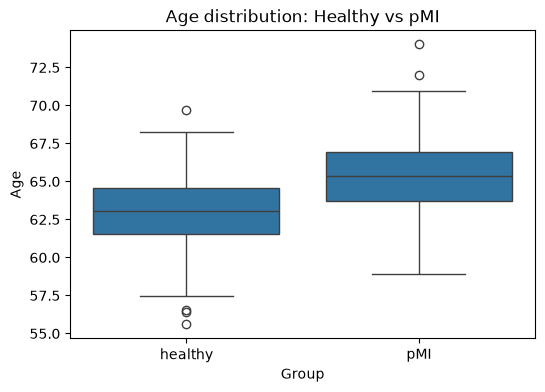

In [5]:
plt.figure(figsize=(6, 4))

sns.boxplot(
    data=df,
    x="MI",
    y="age"
)

plt.xlabel("Group")
plt.ylabel("Age")
plt.title("Age distribution: Healthy vs pMI")

plt.show()

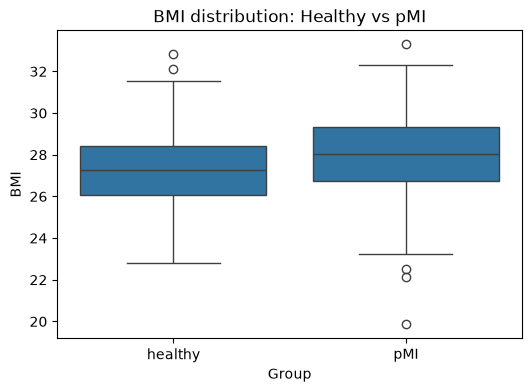

In [6]:
plt.figure(figsize=(6, 4))

sns.boxplot(
    data=df,
    x="MI",
    y="BMI"
)

plt.xlabel("Group")
plt.ylabel("BMI")
plt.title("BMI distribution: Healthy vs pMI")

plt.show()

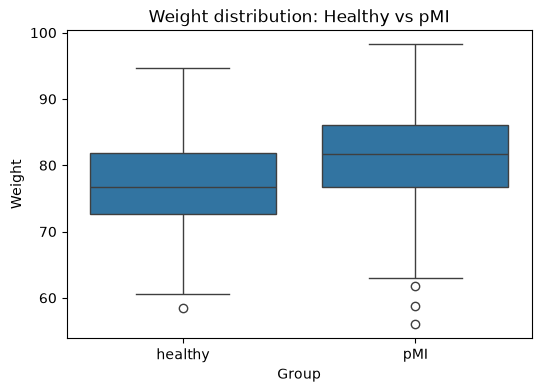

In [7]:
plt.figure(figsize=(6, 4))

sns.boxplot(
    data=df,
    x="MI",
    y="weight"
)

plt.xlabel("Group")
plt.ylabel("Weight")
plt.title("Weight distribution: Healthy vs pMI")

plt.show()

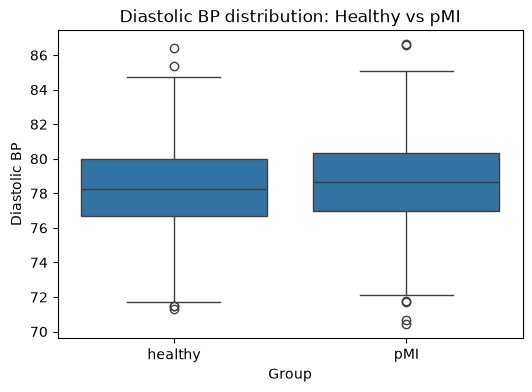

In [8]:
plt.figure(figsize=(6, 4))

sns.boxplot(
    data=df,
    x="MI",
    y="diastolic_BP"
)

plt.xlabel("Group")
plt.ylabel("Diastolic BP")
plt.title("Diastolic BP distribution: Healthy vs pMI")

plt.show()

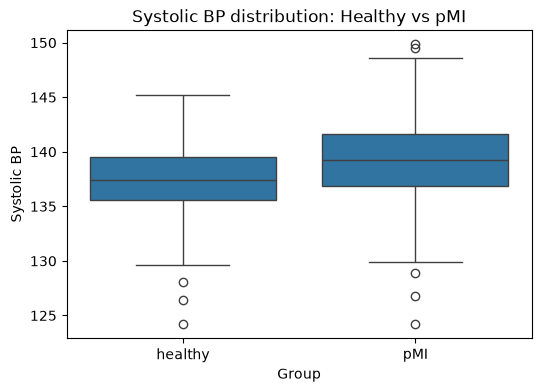

In [10]:
plt.figure(figsize=(6, 4))

sns.boxplot(
    data=df,
    x="MI",
    y="systolic_BP"
)

plt.xlabel("Group")
plt.ylabel("Systolic BP")
plt.title("Systolic BP distribution: Healthy vs pMI")

plt.show()

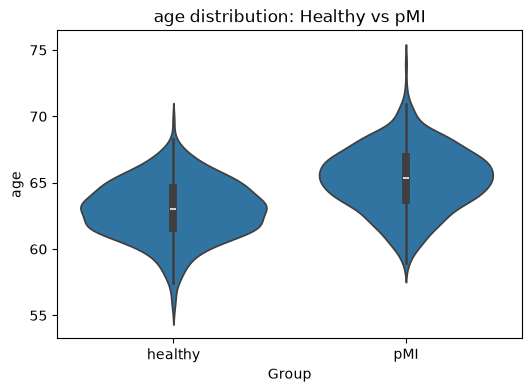

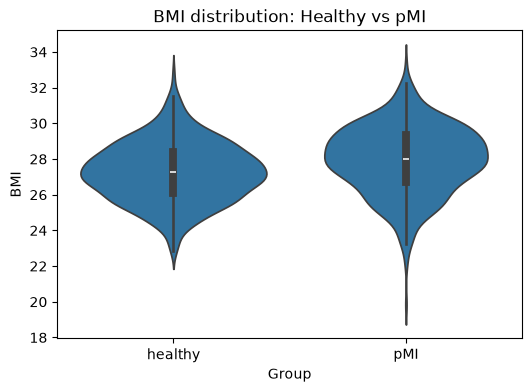

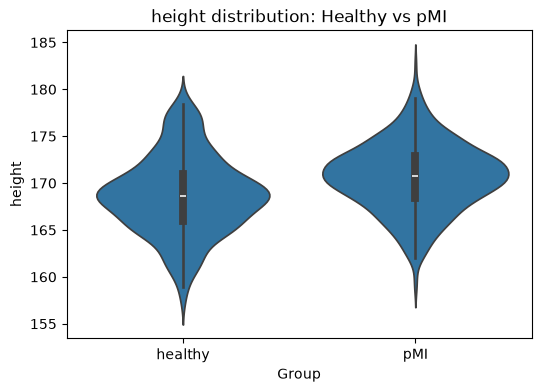

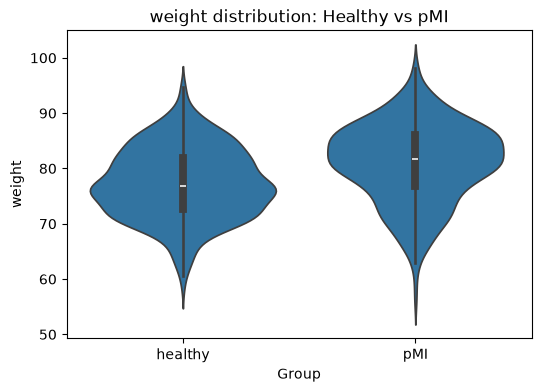

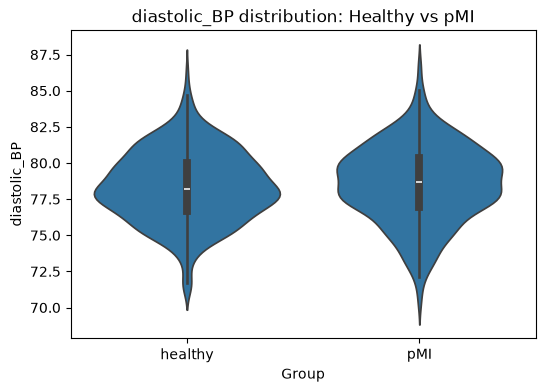

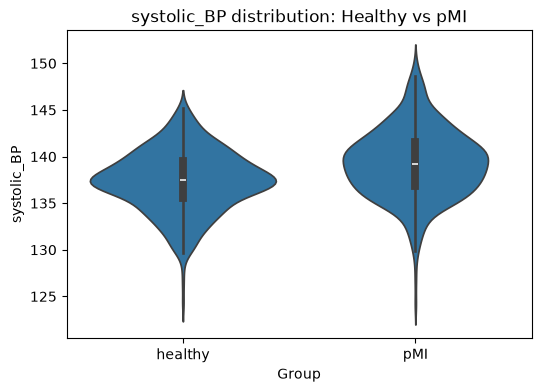

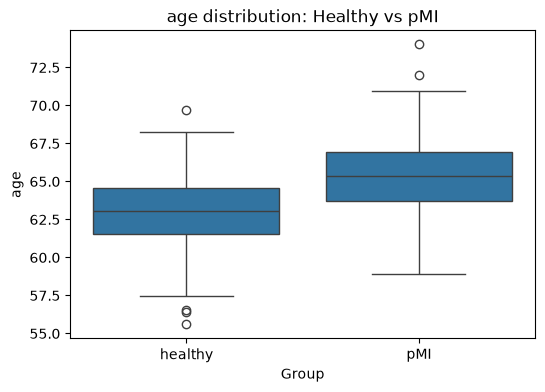

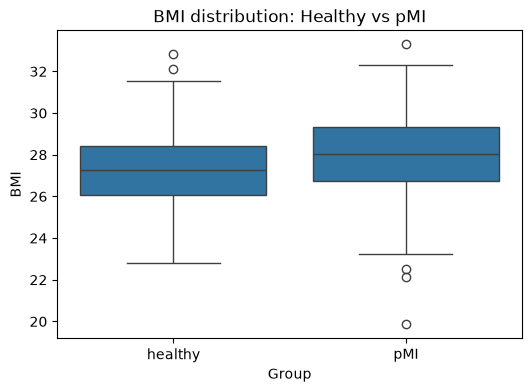

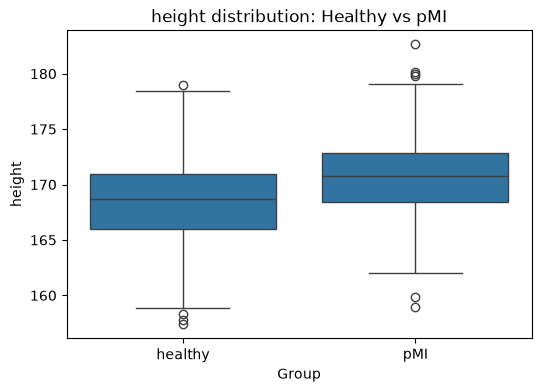

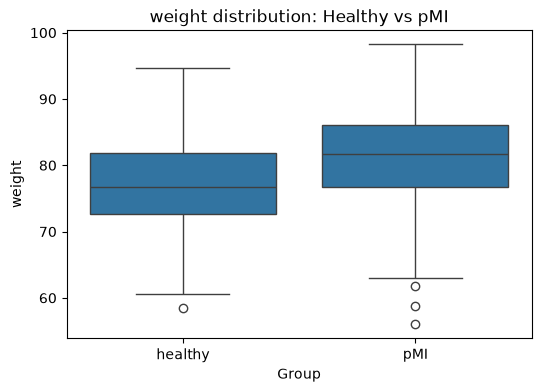

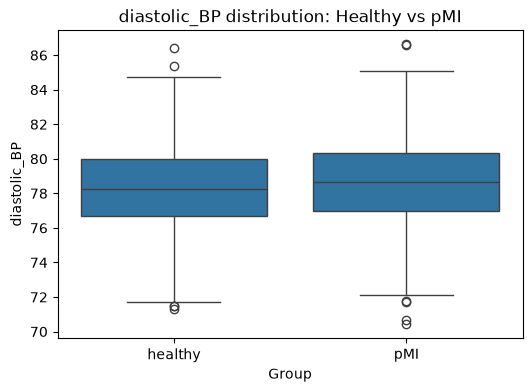

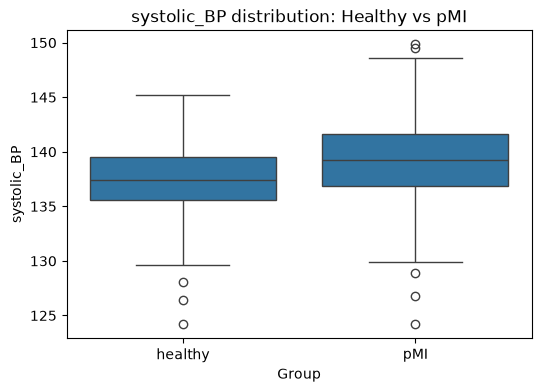

In [13]:
features = [
    "age",
    "BMI",
    "height",
    "weight",
    "diastolic_BP",
    "systolic_BP"
]

for feature in features:
    plt.figure(figsize=(6, 4))

    sns.boxplot(
        data=df,
        x="MI",
        y=feature
    )

    plt.xlabel("Group")
    plt.ylabel(feature)
    plt.title(f"{feature} distribution: Healthy vs pMI")

    plt.show()

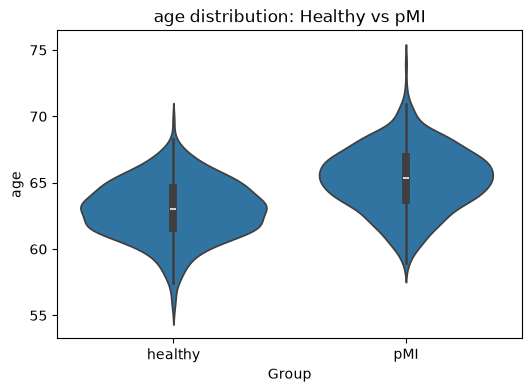

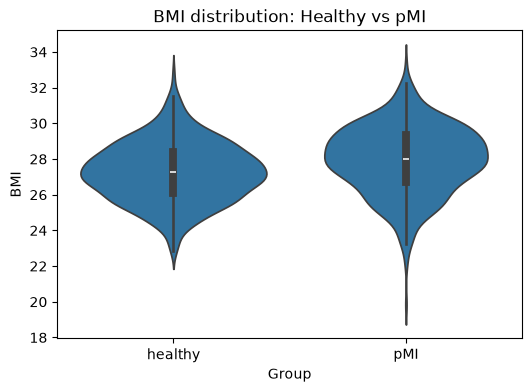

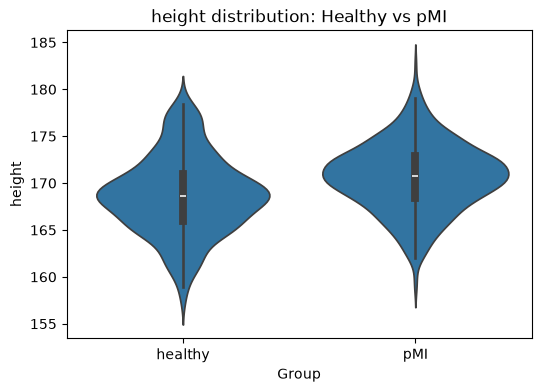

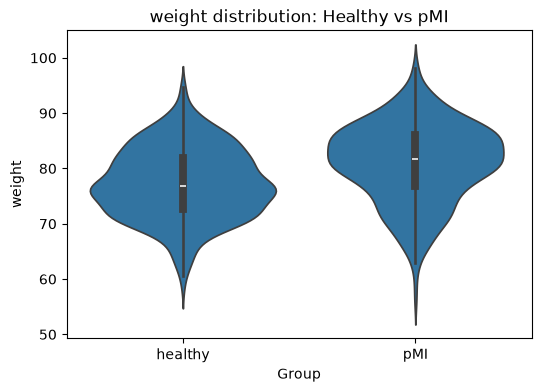

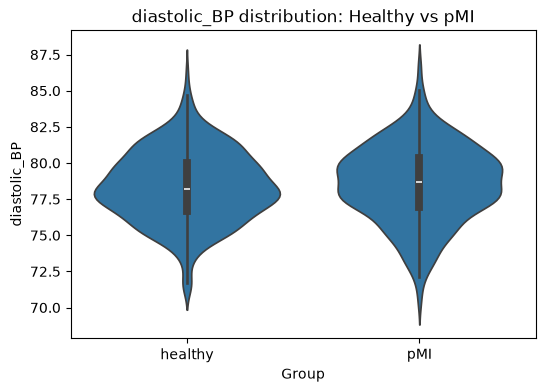

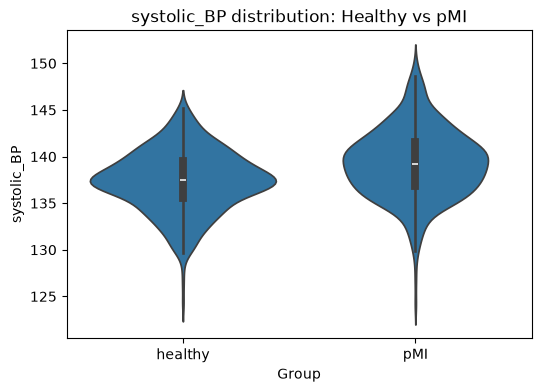

In [ ]:
features = [
    "age",
    "BMI",
    "height",
    "weight",
    "diastolic_BP",
    "systolic_BP"
]

for feature in features:
    plt.figure(figsize=(6, 4))

    sns.violinplot(
        data=df,
        x="MI",
        y=feature,
        inner="box"
    )

    plt.xlabel("Group")
    plt.ylabel(feature)
    plt.title(f"{feature} distribution: Healthy vs pMI")


    plt.show()

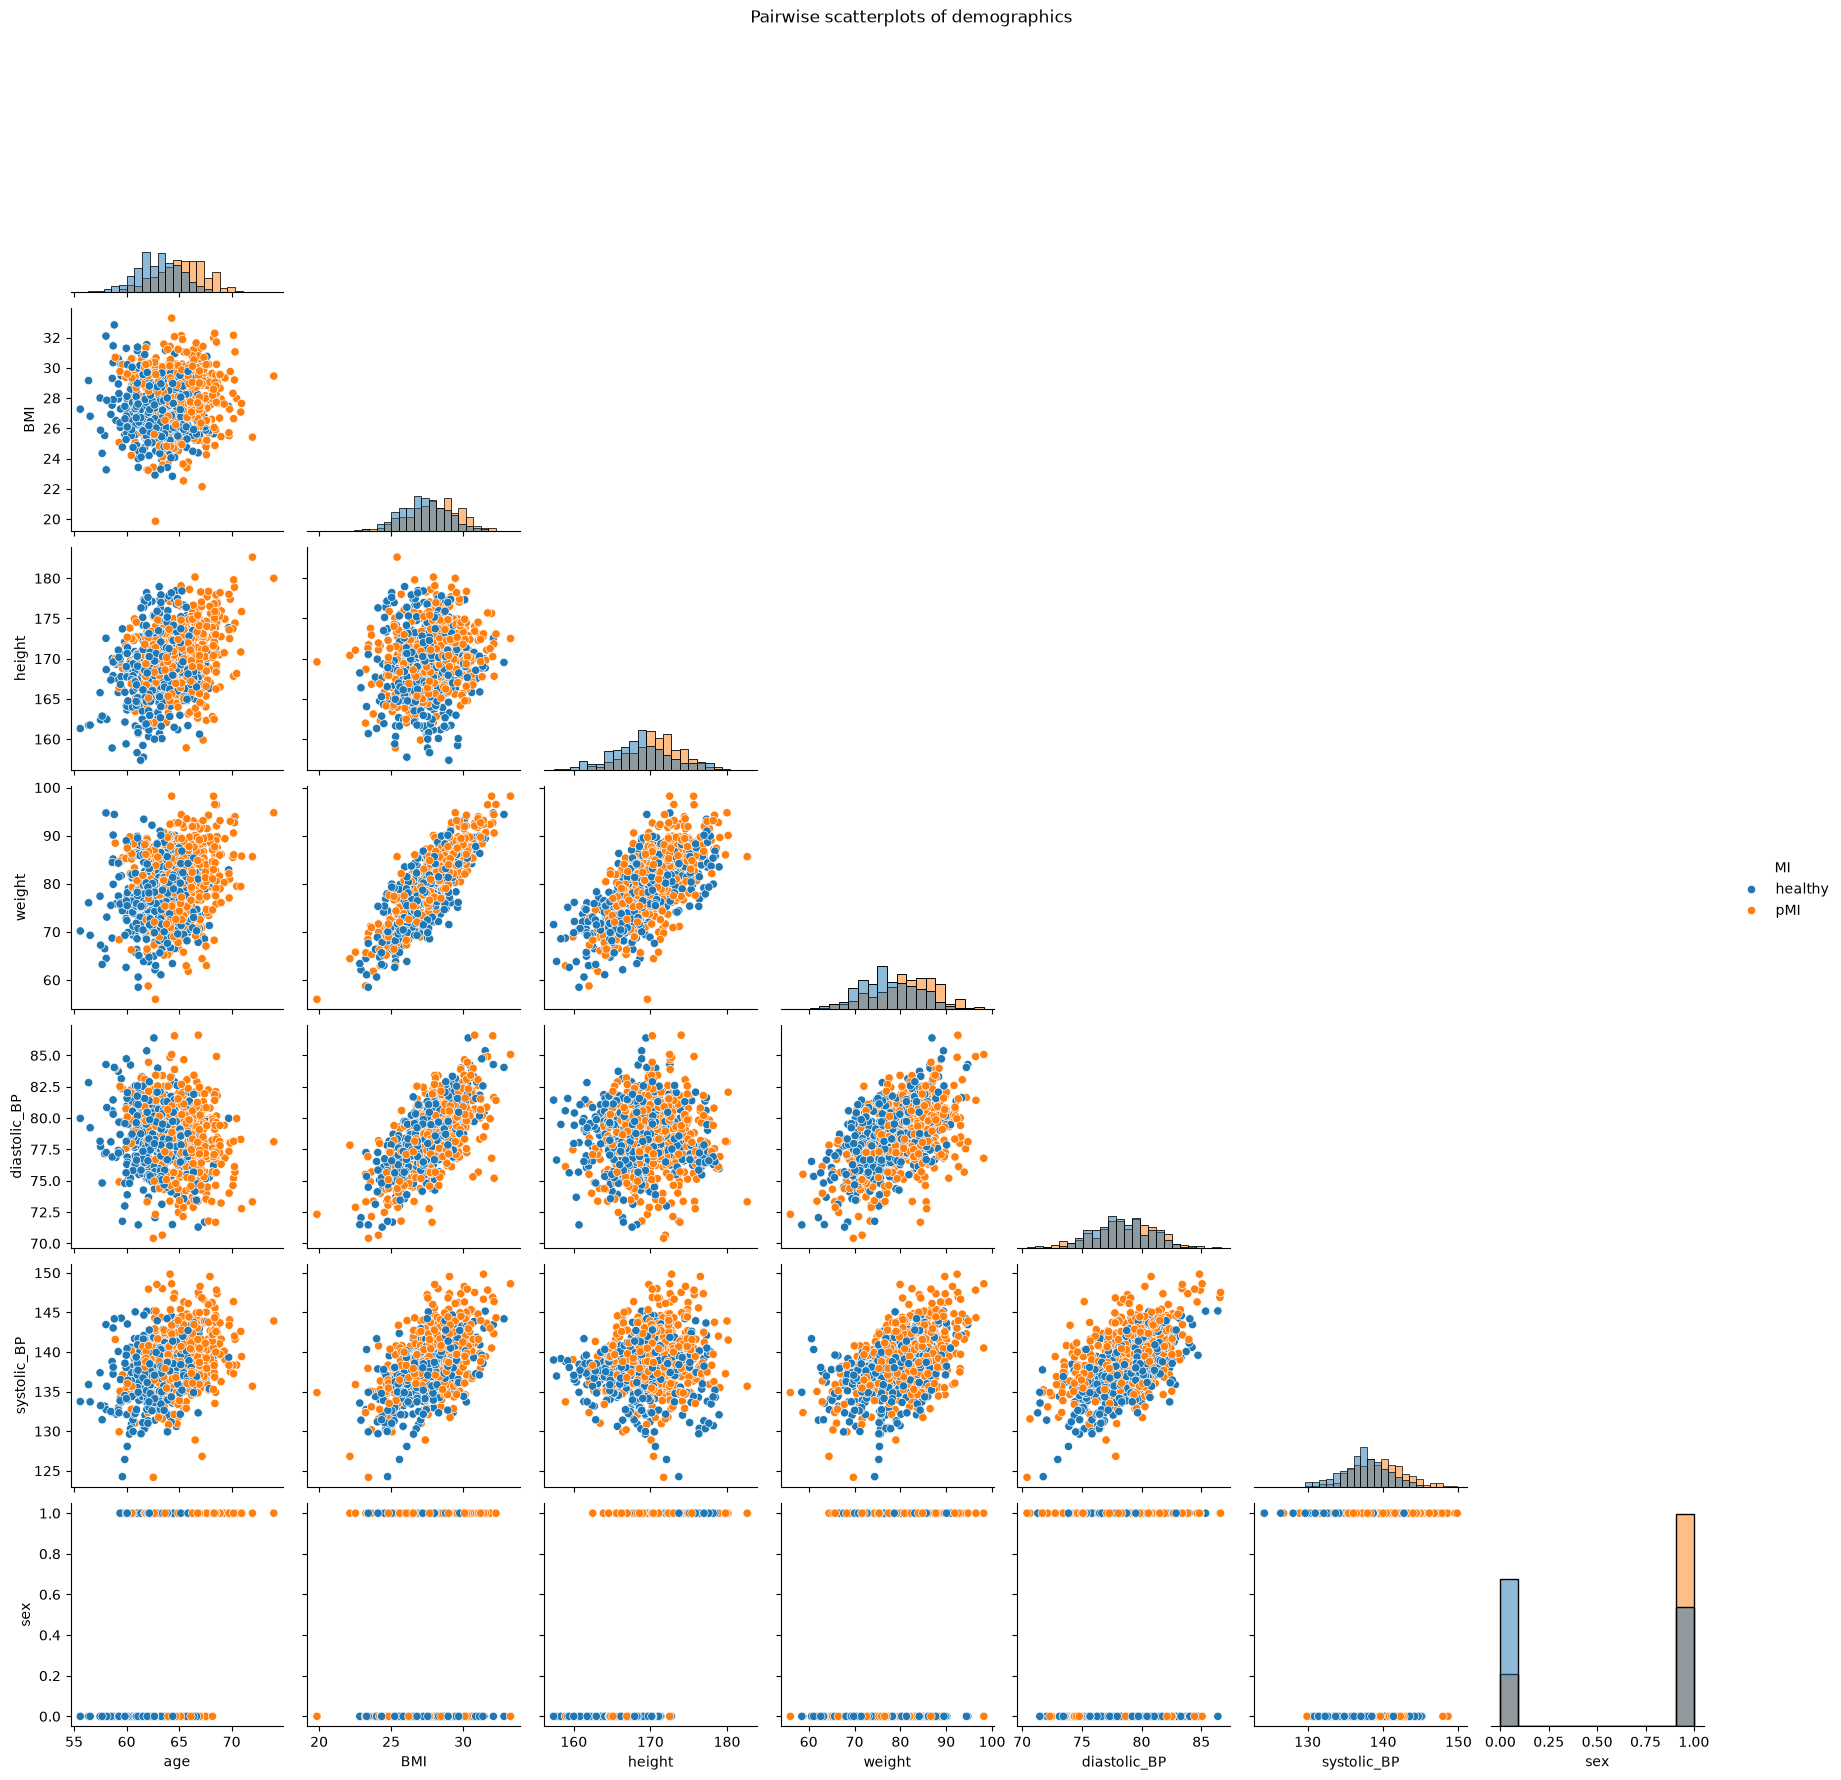

In [23]:

plot_df = df.drop(columns=["Unnamed: 0"])
sns.pairplot(plot_df, hue = 'MI', diag_kind = 'hist', corner = True)
plt.suptitle("Pairwise scatterplots of demographics", y=1.02)


plt.savefig(
    "../results/pairwise_correlations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [24]:
numeric_df = df.select_dtypes(include="number").drop(
    columns=["Unnamed: 0"],
    errors="ignore"
)

numeric_df.corr()

,age,BMI,height,weight,diastolic_BP,systolic_BP
age,1.000000,0.066925,0.325586,0.239501,-0.167616,0.350440
BMI,0.066925,1.000000,0.175875,0.842205,0.682752,0.557372
height,0.325586,0.175875,1.000000,0.676929,0.048915,0.136160
weight,0.239501,0.842205,0.676929,1.000000,0.528511,0.485506
diastolic_BP,-0.167616,0.682752,0.048915,0.528511,1.000000,0.554683
systolic_BP,0.350440,0.557372,0.136160,0.485506,0.554683,1.000000


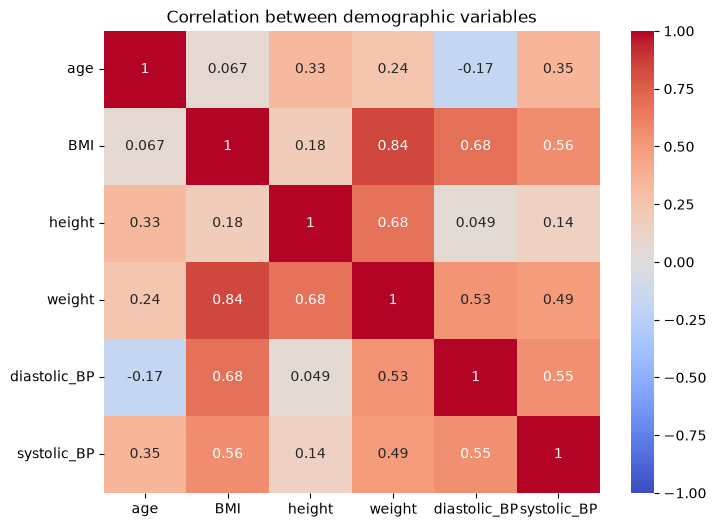

In [26]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation between demographic variables")


plt.savefig(
    "../results/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()